[ Info: Precompiling IJuliaExt [388d8a6b-6fe4-50b5-a981-2e7a5d676f34]
Precompiling packages...
   2.6 s  ✓ GR → IJuliaExt
   4.2 s  ✓ Plots → IJuliaExt
  2 dependencies successfully precompiled in 5 seconds. 175 already precompiled.


[1.0, 1.0412786454705882, 1.1547261208857074, 1.3239094565289573, 1.5363817850042807, 1.8214892991042442, 2.187139297776232, 2.6627632840763393, 2.6644562419335163]


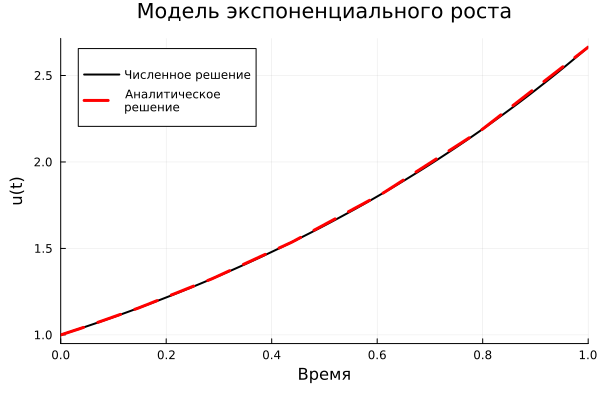

In [1]:
using Plots
using DifferentialEquations
# задаём описание модели с начальными условиями:
a = 0.98
f(u,p,t) = a*u
u0 = 1.0
# задаём интервал времени:
tspan = (0.0,1.0)
prob = ODEProblem(f,u0,tspan)
sol = solve(prob)
plot(sol, linewidth=5,title="Модель экспоненциального роста", xaxis="Время",yaxis="u(t)",label="u(t)")
plot!(sol.t, t->1.0*exp(a*t),lw=3,ls=:dash,label="Аналитическое решение")
# задаём точность решения:
sol = solve(prob,abstol=1e-8,reltol=1e-8)
println(sol)
# строим график:
plot(sol, lw=2, color="black", title="Модель экспоненциального роста",
xaxis="Время",yaxis="u(t)",label="Численное решение")
plot!(sol.t,
t->1.0*exp(a*t),lw=3,ls=:dash,color="red",label="Аналитическое
решение")

┌ Warning: To maintain consistency with solution indexing, keyword argument vars will be removed in a future version. Please use keyword argument idxs instead.
│   caller = ip:0x0
└ @ Core :-1


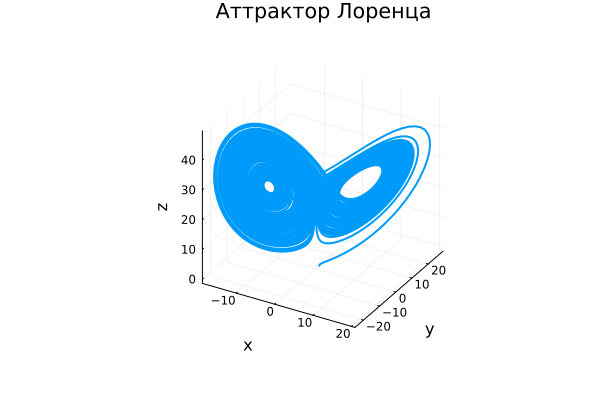

In [4]:
# задаём описание модели:
function lorenz!(du,u,p,t)
σ,ρ,β = p
du[1] = σ*(u[2]-u[1])
du[2] = u[1]*(ρ-u[3]) - u[2]
du[3] = u[1]*u[2] - β*u[3]
end
# задаём начальное условие:
u0 = [1.0,0.0,0.0]
# задаём знанчения параметров:
p = (10,28,8/3)
# задаём интервал времени:
tspan = (0.0,100.0)
# решение:
prob = ODEProblem(lorenz!,u0,tspan,p)
sol = solve(prob)
# строим график:
plot(sol, vars=(1,2,3), lw=2, title="Аттрактор Лоренца", xaxis="x",yaxis="y", zaxis="z",legend=false)

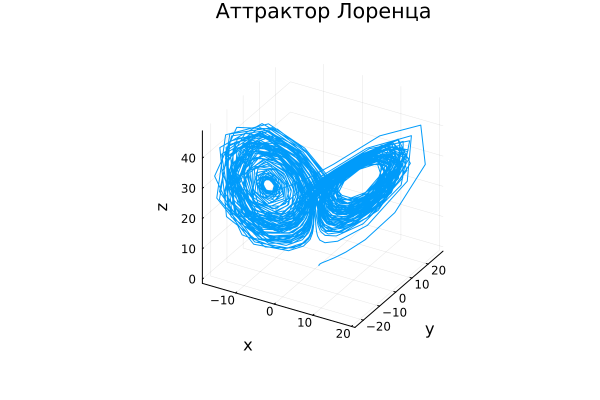

In [5]:
# отключаем интерполяцию:
plot(sol,vars=(1,2,3),denseplot=false, lw=1, title="Аттрактор Лоренца", xaxis="x",yaxis="y", zaxis="z",legend=false)

[ Info: Precompiling MTKOrdinaryDiffEqRosenbrockExt [0f40791e-d995-5b09-b3d4-5773d59d5a9c]
Precompiling packages...
  36.8 s  ✓ ModelingToolkit → MTKOrdinaryDiffEqRosenbrockExt
  1 dependency successfully precompiled in 40 seconds. 268 already precompiled.
[ Info: Precompiling MTKOrdinaryDiffEqBDFExt [8b55282c-52e6-539f-a808-4945cb66c42f]
Precompiling packages...
  57.5 s  ✓ ModelingToolkit → MTKOrdinaryDiffEqBDFExt
  1 dependency successfully precompiled in 60 seconds. 274 already precompiled.
[ Info: Precompiling MTKOrdinaryDiffEqDefaultExt [329a8989-dbea-543d-8df4-ca816669a8a3]
Precompiling packages...
  49.2 s  ✓ ModelingToolkit → MTKOrdinaryDiffEqTsit5Ext
 149.3 s  ✓ ModelingToolkit → MTKOrdinaryDiffEqDefaultExt
  2 dependencies successfully precompiled in 153 seconds. 281 already precompiled.
[ Info: Precompiling MTKOrdinaryDiffEqRosenbrockNonlinearSolveExt [7a4e828a-520e-5992-92e1-6604212b63a1]
Precompiling packages...
  50.6 s  ✓ ModelingToolkit → MTKOrdinaryDiffEqRosenbrockNon

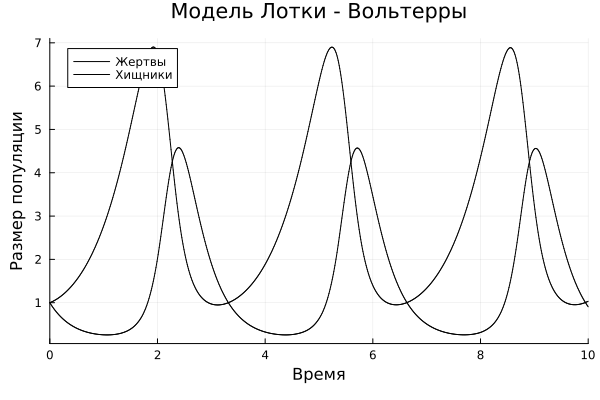

In [19]:
# задаём описание модели:
using ParameterizedFunctions, DifferentialEquations, Plots;
lv! = @ode_def LotkaVolterra begin
dx = a*x - b*x*y
dy = -c*y + d*x*y
end a b c d
# задаём начальное условие:
u0 = [1.0,1.0]
# задаём знанчения параметров:
p = (1.5,1.0,3.0,1.0)
# задаём интервал времени:
tspan = (0.0,10.0)
# решение:
prob = ODEProblem(lv!,u0,tspan,p)
sol = solve(prob)
plot(sol, label = ["Жертвы" "Хищники"], color="black", ls=[:solid
:dash], title="Модель Лотки - Вольтерры", xaxis="Время",yaxis="Размер популяции")


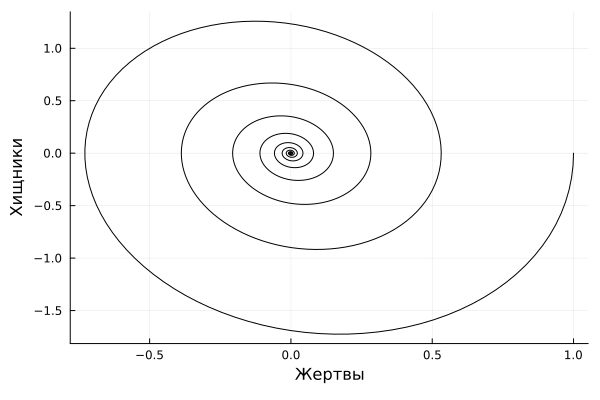

In [24]:
# фазовый портрет:
plot(sol,vars=(1,2), color="black", xaxis="Жертвы",yaxis="Хищники", legend=false)

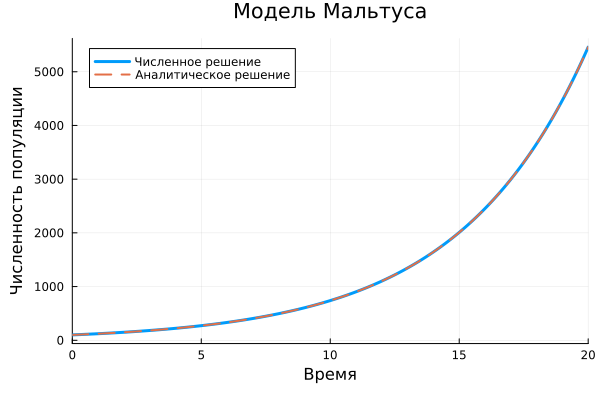

In [1]:
#1
using DifferentialEquations
using Plots

# Параметры модели
b = 0.35
c = 0.15
a = b - c

x0 = 100.0
tspan = (0.0, 20.0)

# Дифференциальное уравнение
f(x, p, t) = a * x

# Численное решение
prob = ODEProblem(f, x0, tspan)
sol = solve(prob)

# Аналитическое решение
t = range(0, 20, length=300)
x_exact = x0 .* exp.(a .* t)

# График
plot(sol, linewidth=3,
    label="Численное решение",
    title="Модель Мальтуса",
    xlabel="Время",
    ylabel="Численность популяции")

plot!(t, x_exact, linestyle=:dash,
    linewidth=2, label="Аналитическое решение")

[ Info: Saved animation to /home/srluipp/work/study/2026-2/2026-2==study--computer-practice/2026-2-study-computer-practice/labs/lab06/project/malthus.gif


Plots.AnimatedGif("/home/srluipp/work/study/2026-2/2026-2==study--computer-practice/2026-2-study-computer-practice/labs/lab06/project/malthus.gif")
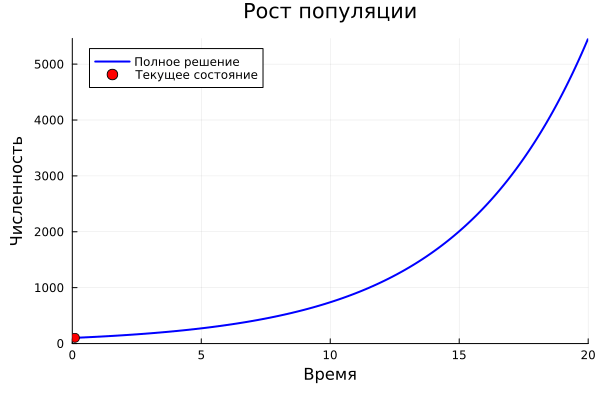

In [2]:
#1
anim = @animate for ti in 0.1:0.1:20
    plot(t, x_exact,
        linewidth=2,
        color=:blue,
        label="Полное решение",
        title="Рост популяции",
        xlabel="Время",
        ylabel="Численность")

    scatter!([ti], [x0 * exp(a * ti)],
        markersize=5,
        color=:red,
        label="Текущее состояние")

    xlims!(0, 20)
    ylims!(0, maximum(x_exact))
end

gif(anim, "malthus.gif", fps=20)

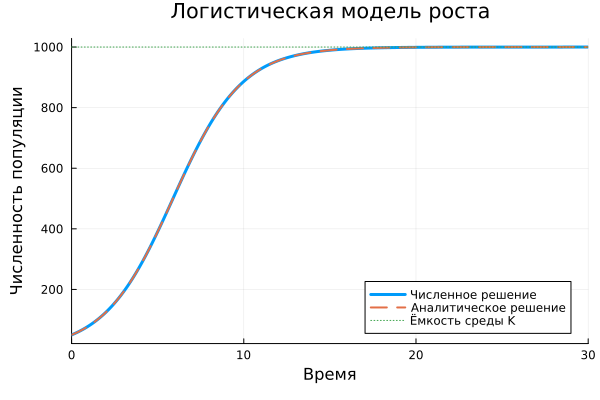

In [3]:
#2
using DifferentialEquations
using Plots

r = 0.5
K = 1000.0
x0 = 50.0

tspan = (0.0, 30.0)

f(x, p, t) = r * x * (1 - x / K)

prob = ODEProblem(f, x0, tspan)
sol = solve(prob)

t = range(0, 30, length=300)

x_exact = K ./ (1 .+ ((K - x0) / x0) .* exp.(-r .* t))

plot(sol, linewidth=3,
    label="Численное решение",
    title="Логистическая модель роста",
    xlabel="Время",
    ylabel="Численность популяции")

plot!(t, x_exact, linestyle=:dash,
    linewidth=2, label="Аналитическое решение")

hline!([K], linestyle=:dot,
    label="Ёмкость среды K")

[ Info: Saved animation to /home/srluipp/work/study/2026-2/2026-2==study--computer-practice/2026-2-study-computer-practice/labs/lab06/project/logistic.gif


Plots.AnimatedGif("/home/srluipp/work/study/2026-2/2026-2==study--computer-practice/2026-2-study-computer-practice/labs/lab06/project/logistic.gif")
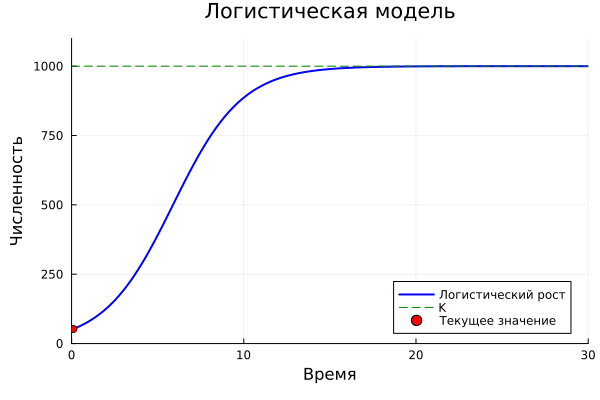

In [4]:
#2
anim = @animate for ti in 0.1:0.1:30
    plot(t, x_exact,
        linewidth=2,
        color=:blue,
        label="Логистический рост",
        title="Логистическая модель",
        xlabel="Время",
        ylabel="Численность")

    hline!([K], linestyle=:dash, color=:green,
        label="K")

    scatter!([ti], [K / (1 + ((K-x0)/x0)*exp(-r*ti))],
        color=:red, label="Текущее значение")

    xlims!(0, 30)
    ylims!(0, 1100)
end

gif(anim, "logistic.gif", fps=20)

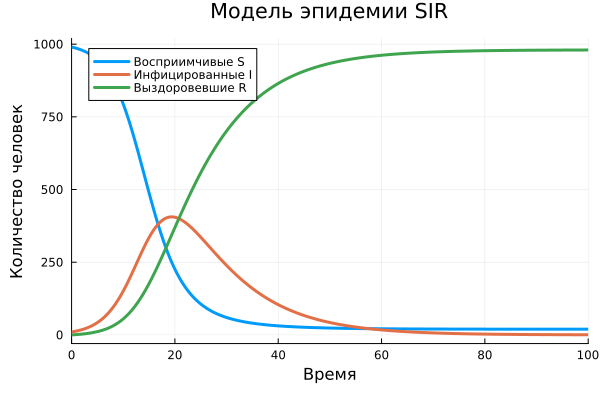

In [5]:
#3
# Параметры
β = 0.0004
ν = 0.1

u0 = [990.0, 10.0, 0.0]
tspan = (0.0, 100.0)

# SIR-модель
function sir!(du, u, p, t)
    S, I, R = u
    β, ν = p

    du[1] = -β * S * I
    du[2] = β * S * I - ν * I
    du[3] = ν * I
end

prob = ODEProblem(sir!, u0, tspan, (β, ν))
sol = solve(prob)

# График
plot(sol, linewidth=3,
    label=["Восприимчивые S" "Инфицированные I" "Выздоровевшие R"],
    title="Модель эпидемии SIR",
    xlabel="Время",
    ylabel="Количество человек")

[ Info: Saved animation to /home/srluipp/work/study/2026-2/2026-2==study--computer-practice/2026-2-study-computer-practice/labs/lab06/project/sir.gif


Plots.AnimatedGif("/home/srluipp/work/study/2026-2/2026-2==study--computer-practice/2026-2-study-computer-practice/labs/lab06/project/sir.gif")
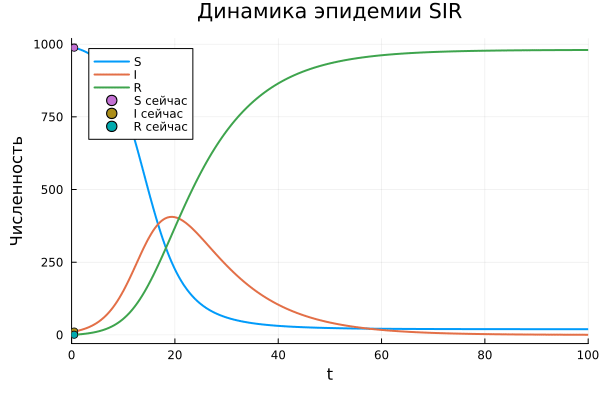

In [6]:
#3
anim = @animate for ti in 0.5:0.5:100
    plot(sol, idxs=1, linewidth=2,
        label="S",
        title="Динамика эпидемии SIR",
        xlabel="Время", ylabel="Численность")

    plot!(sol, idxs=2, linewidth=2, label="I")
    plot!(sol, idxs=3, linewidth=2, label="R")

    scatter!([ti], [sol(ti)[1]], label="S сейчас")
    scatter!([ti], [sol(ti)[2]], label="I сейчас")
    scatter!([ti], [sol(ti)[3]], label="R сейчас")
end

gif(anim, "sir.gif", fps=15)

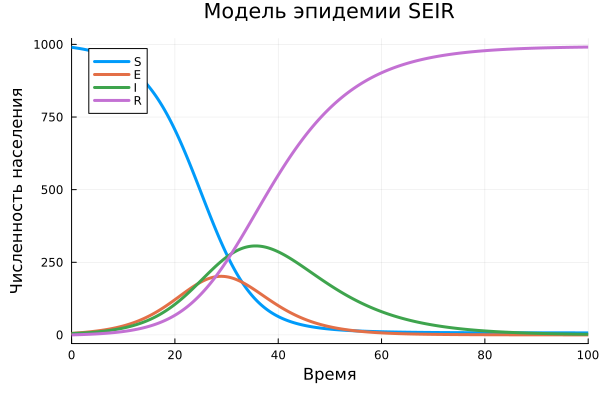

In [7]:
#4
N = 1000.0

β = 0.5
δ = 0.2
γ = 0.1

u0 = [990.0, 5.0, 5.0, 0.0]
tspan = (0.0, 100.0)

function seir!(du, u, p, t)
    S, E, I, R = u
    β, δ, γ, N = p

    du[1] = -β * S * I / N
    du[2] = β * S * I / N - δ * E
    du[3] = δ * E - γ * I
    du[4] = γ * I
end

prob = ODEProblem(seir!, u0, tspan, (β, δ, γ, N))
sol = solve(prob)

plot(sol, linewidth=3,
    label=["S" "E" "I" "R"],
    title="Модель эпидемии SEIR",
    xlabel="Время",
    ylabel="Численность населения")

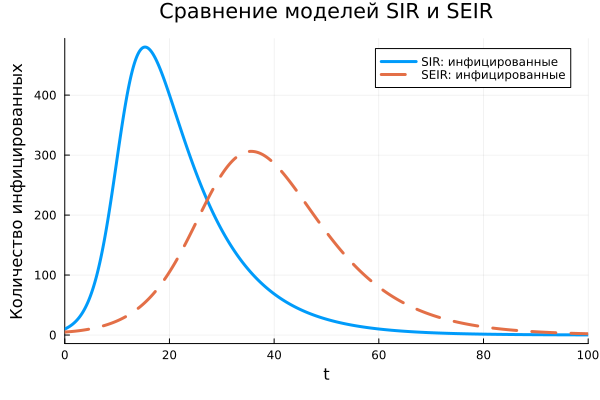

In [8]:
#4
# Решение SIR для сравнения
sir_u0 = [990.0, 10.0, 0.0]
sir_p = (0.5, 0.1)

function sir_compare!(du, u, p, t)
    S, I, R = u
    β, γ = p

    du[1] = -β * S * I / N
    du[2] = β * S * I / N - γ * I
    du[3] = γ * I
end

sir_prob = ODEProblem(sir_compare!, sir_u0, tspan, sir_p)
sir_sol = solve(sir_prob)

plot(sir_sol, idxs=2,
    linewidth=3, label="SIR: инфицированные",
    title="Сравнение моделей SIR и SEIR",
    xlabel="Время",
    ylabel="Количество инфицированных")

plot!(sol, idxs=3,
    linewidth=3, linestyle=:dash,
    label="SEIR: инфицированные")

Аналитическая точка равновесия:
X1* = 0.2
X2* = 0.6000000000000001


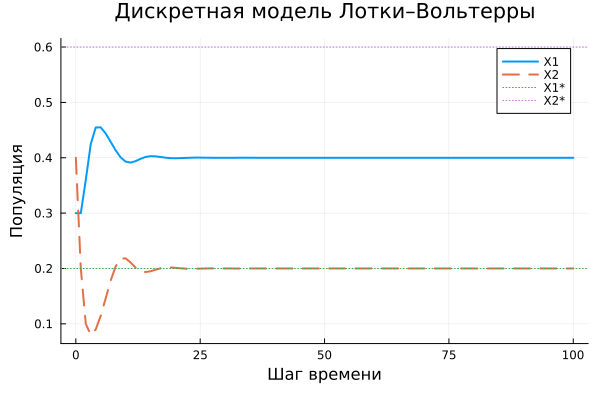

In [10]:
#5
using Plots

# Параметры
a = 2.0
c = 1.0
d = 5.0

# Аналитическая точка равновесия
X1_eq = c / d
X2_eq = a * (1 - X1_eq) - 1

println("Аналитическая точка равновесия:")
println("X1* = ", X1_eq)
println("X2* = ", X2_eq)

# Начальные условия
X1_0 = 0.3
X2_0 = 0.4

n = 100

X1 = zeros(n+1)
X2 = zeros(n+1)

X1[1] = X1_0
X2[1] = X2_0

# Численное решение методом последовательных итераций
for k in 1:n
    X1[k+1] = a*X1[k]*(1-X1[k]) - X1[k]*X2[k]
    X2[k+1] = -c*X2[k] + d*X1[k]*X2[k]
end

# График численного решения
plot(0:n, X1,
    linewidth=2,
    label="X1",
    title="Дискретная модель Лотки–Вольтерры",
    xlabel="Шаг времени",
    ylabel="Популяция")

plot!(0:n, X2,
    linewidth=2,
    linestyle=:dash,
    label="X2")

hline!([X1_eq], linestyle=:dot,
    label="X1*")

hline!([X2_eq], linestyle=:dot,
    label="X2*")

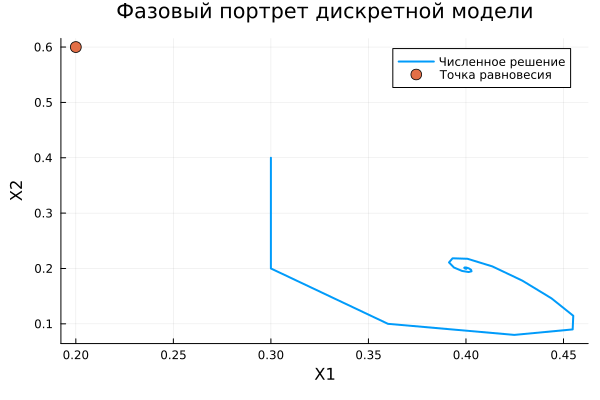

In [11]:
plot(X1, X2,
    linewidth=2,
    label="Численное решение",
    xlabel="X1",
    ylabel="X2",
    title="Фазовый портрет дискретной модели")

scatter!([X1_eq], [X2_eq],
    markersize=6,
    label="Точка равновесия")

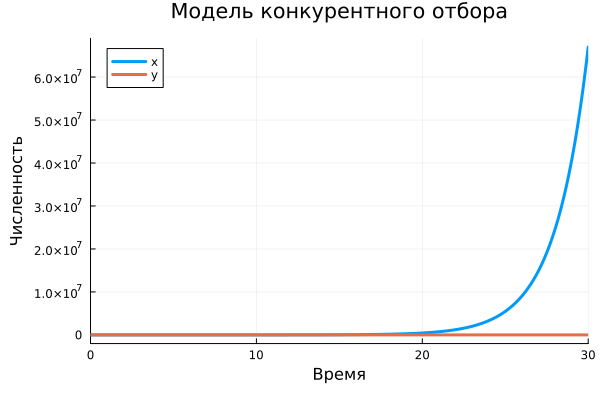

In [12]:
#6
α = 0.5
β = 0.01

u0 = [40.0, 20.0]
tspan = (0.0, 30.0)

function competition!(du, u, p, t)
    x, y = u
    α, β = p

    du[1] = α*x - β*x*y
    du[2] = α*y - β*x*y
end

prob = ODEProblem(competition!, u0, tspan, (α, β))
sol = solve(prob)

# Динамика
plot(sol, linewidth=3,
    label=["x" "y"],
    title="Модель конкурентного отбора",
    xlabel="Время",
    ylabel="Численность")

┌ Warning: To maintain consistency with solution indexing, keyword argument vars will be removed in a future version. Please use keyword argument idxs instead.
│   caller = ip:0x0
└ @ Core :-1


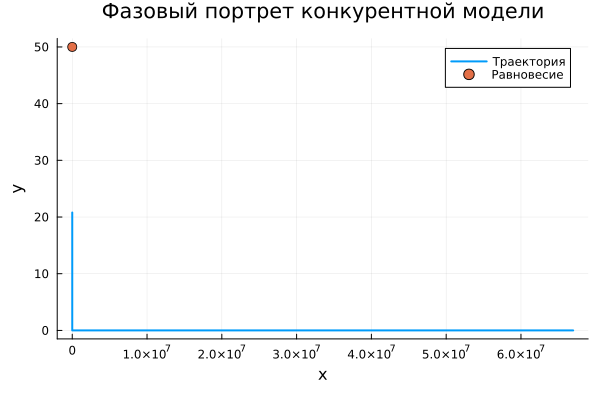

In [13]:
plot(sol, vars=(1,2),
    linewidth=2,
    label="Траектория",
    xlabel="x",
    ylabel="y",
    title="Фазовый портрет конкурентной модели")

scatter!([α/β], [α/β],
    label="Равновесие",
    markersize=5)

[ Info: Saved animation to /home/srluipp/work/study/2026-2/2026-2==study--computer-practice/2026-2-study-computer-practice/labs/lab06/project/competition.gif


Plots.AnimatedGif("/home/srluipp/work/study/2026-2/2026-2==study--computer-practice/2026-2-study-computer-practice/labs/lab06/project/competition.gif")
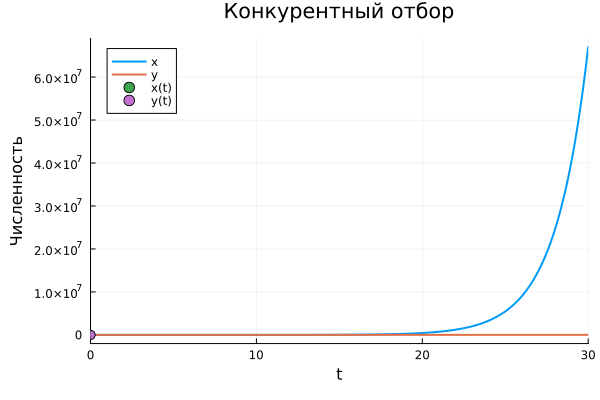

In [14]:
t = range(0, 30, length=300)

anim = @animate for ti in t
    plot(sol, idxs=1,
        linewidth=2,
        label="x",
        title="Конкурентный отбор",
        xlabel="Время",
        ylabel="Численность")

    plot!(sol, idxs=2,
        linewidth=2,
        label="y")

    scatter!([ti], [sol(ti)[1]],
        label="x(t)",
        markersize=5)

    scatter!([ti], [sol(ti)[2]],
        label="y(t)",
        markersize=5)
end

gif(anim, "competition.gif", fps=20)

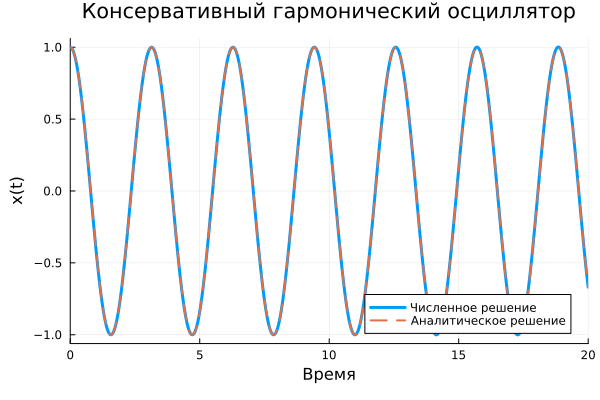

In [15]:
#7
using DifferentialEquations
using Plots

ω0 = 2.0
x0 = 1.0
y0 = 0.0

tspan = (0.0, 20.0)

function oscillator!(du, u, p, t)
    x, y = u
    ω0 = p

    du[1] = y
    du[2] = -ω0^2 * x
end

prob = ODEProblem(oscillator!, [x0, y0], tspan, ω0)
sol = solve(prob)

# Аналитическое решение
t = range(0, 20, length=500)

x_exact = x0 .* cos.(ω0 .* t) .+
          (y0 / ω0) .* sin.(ω0 .* t)

y_exact = -x0 * ω0 .* sin.(ω0 .* t) .+
          y0 .* cos.(ω0 .* t)

# График координаты
plot(sol, idxs=1,
    linewidth=3,
    label="Численное решение",
    title="Консервативный гармонический осциллятор",
    xlabel="Время",
    ylabel="x(t)")

plot!(t, x_exact,
    linestyle=:dash,
    linewidth=2,
    label="Аналитическое решение")

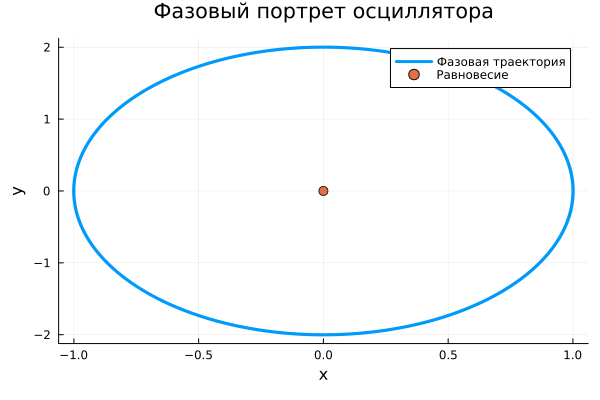

In [16]:
plot(sol, vars=(1,2),
    linewidth=3,
    label="Фазовая траектория",
    title="Фазовый портрет осциллятора",
    xlabel="x",
    ylabel="y")

scatter!([0], [0],
    label="Равновесие",
    markersize=5)

[ Info: Saved animation to /home/srluipp/work/study/2026-2/2026-2==study--computer-practice/2026-2-study-computer-practice/labs/lab06/project/oscillator.gif


Plots.AnimatedGif("/home/srluipp/work/study/2026-2/2026-2==study--computer-practice/2026-2-study-computer-practice/labs/lab06/project/oscillator.gif")
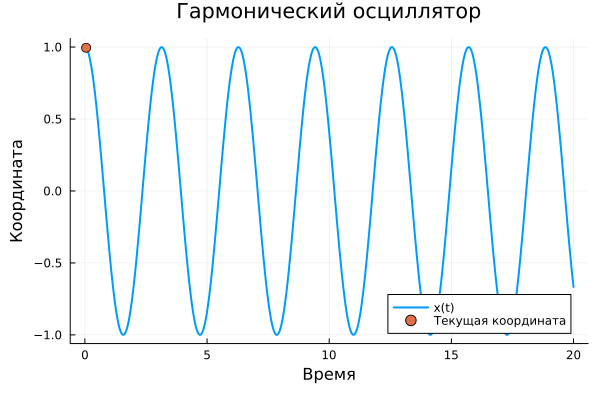

In [17]:
anim = @animate for ti in 0.05:0.05:20
    x_now = x0*cos(ω0*ti) + (y0/ω0)*sin(ω0*ti)
    y_now = -x0*ω0*sin(ω0*ti) + y0*cos(ω0*ti)

    plot(t, x_exact,
        linewidth=2,
        label="x(t)",
        title="Гармонический осциллятор",
        xlabel="Время",
        ylabel="Координата")

    scatter!([ti], [x_now],
        markersize=5,
        label="Текущая координата")
end

gif(anim, "oscillator.gif", fps=20)

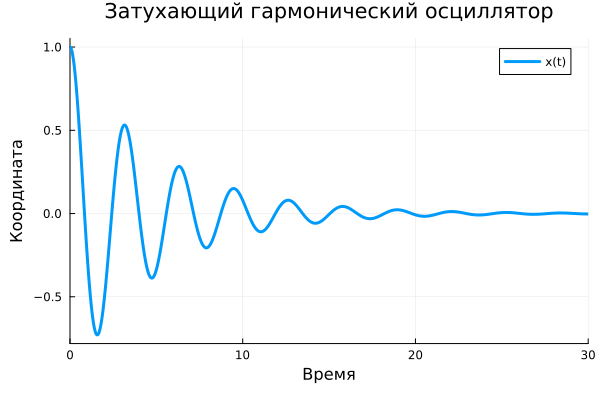

In [20]:
#8
ω0 = 2.0
γ = 0.2

x0 = 1.0
y0 = 0.0

tspan = (0.0, 30.0)

function damped_oscillator!(du, u, p, t)
    x, y = u
    ω0, γ = p

    du[1] = y
    du[2] = -2*γ*y - ω0^2*x
end

prob = ODEProblem(
    damped_oscillator!,
    [x0, y0],
    tspan,
    (ω0, γ)
)

sol = solve(prob)

plot(sol, idxs=1,
    linewidth=3,
    label="x(t)",
    title="Затухающий гармонический осциллятор",
    xlabel="Время",
    ylabel="Координата")

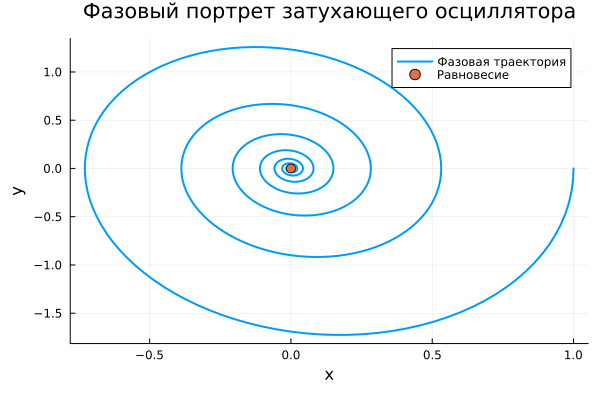

In [21]:
plot(sol, vars=(1,2),
    linewidth=2,
    label="Фазовая траектория",
    title="Фазовый портрет затухающего осциллятора",
    xlabel="x",
    ylabel="y")

scatter!([0], [0],
    label="Равновесие",
    markersize=5)

[ Info: Saved animation to /home/srluipp/work/study/2026-2/2026-2==study--computer-practice/2026-2-study-computer-practice/labs/lab06/project/damped_oscillator.gif


Plots.AnimatedGif("/home/srluipp/work/study/2026-2/2026-2==study--computer-practice/2026-2-study-computer-practice/labs/lab06/project/damped_oscillator.gif")
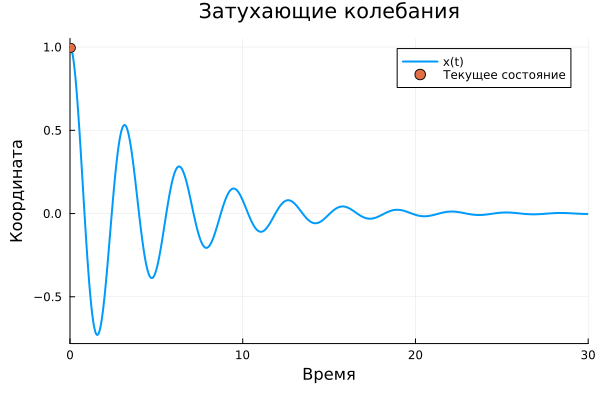

In [22]:
anim = @animate for ti in 0.05:0.05:30
    x_now = sol(ti)[1]

    plot(sol, idxs=1,
        linewidth=2,
        label="x(t)",
        title="Затухающие колебания",
        xlabel="Время",
        ylabel="Координата")

    scatter!([ti], [x_now],
        markersize=5,
        label="Текущее состояние")
end

gif(anim, "damped_oscillator.gif", fps=20)